<div align="center" style="padding:40px 24px;background:linear-gradient(135deg,#0e1a2e 0%,#13223b 100%);border-radius:14px;border-bottom:5px solid #ffd43b;">
  <p style="margin:0;color:#6aaef0;font-family:monospace;font-weight:700;font-size:14px;letter-spacing:.16em;text-transform:uppercase;">The AI Learning Hub · Lição 02 · Machine Learning: fundamentos</p>
  <h1 style="margin:14px 0 6px;color:#f1f5fb;font-size:42px;">04 · Redes neuronais do zero</h1>
  <p style="margin:0;color:#b4c2d8;font-size:18px;">Abrir a caixa-preta</p>
</div>

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/the-ai-learning-hub/02-machine-learning-fundamentals/blob/main/03_neural_networks/notebooks/04_Neural_Networks_From_Scratch.ipynb) [![Slides](https://img.shields.io/badge/slides-Lição_02-ffd43b)](https://the-ai-learning-hub.github.io/02-machine-learning-fundamentals/#redes-neuronais)

## 🎯 Objetivos de aprendizagem

No fim deste notebook és capaz de:

- explicar porque um perceptrão não resolve o XOR e uma camada escondida resolve;
- ler e escrever o *forward*, a *loss* e a retropropagação (*backprop*) de uma rede pequena em NumPy, com as *shapes* de cada passo;
- verificar o gradiente com um *gradient check* e com o autograd do PyTorch;
- ver a fronteira de decisão evoluir durante o treino e o efeito de um *learning rate* pequeno ou grande;
- treinar uma rede em PyTorch (`nn.Module`, *loop* de treino) com split treino/validação e ler as curvas;
- reduzir *overfitting* com *weight decay*, *dropout* e *early stopping*;
- medir CPU vs GPU numa multiplicação de matrizes e decidir quando a CPU chega.

**⏱️ Duração estimada:** ≈ 30 min (+ 10 min na parte 3) · **📋 Pré-requisitos:** notebook 03; álgebra de matrizes básica; ideia de derivada · **▶️ Como usar:** executa cada célula com `Shift`+`Enter`, por ordem.

## 📑 Índice

1. [🧭 Business Understanding (compreensão do negócio)](#sec-1)
2. [🔍 Data Understanding (compreensão dos dados)](#sec-2)
3. [🤖 Modeling (modelação) · Parte 1 — NumPy puro](#sec-3)
4. [🧹 Data Preparation (preparação dos dados) para o PyTorch](#sec-4)
5. [🤖 Modeling · Parte 2 — PyTorch](#sec-5)
6. [📏 Evaluation (avaliação): curvas e regularização](#sec-6)
7. [🚀 Deployment · Parte 3 — CPU vs GPU](#sec-7)
8. [🧱 Limites e extensões](#sec-8)
9. [✏️ Exercícios](#sec-9)
10. [📌 Resumo](#sec-10)
11. [📚 Para saber mais](#sec-11)

<a id="sec-0"></a>

## ⚙️ Preparar o ambiente

In [1]:
# ⚙️ Preparar o ambiente: funciona localmente (VS Code/Jupyter) e no Google Colab
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    ROOT = Path("/content/02-machine-learning-fundamentals")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/the-ai-learning-hub/02-machine-learning-fundamentals.git",
                        str(ROOT)], check=True)
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir() and (p / "data").is_dir())

try:  # o Colab já traz tudo; localmente usa `uv sync` (ver README)
    import sklearn, seaborn  # noqa: F401
except ImportError:  # plano B: instala as dependências declaradas no pyproject.toml
    import tomllib
    deps = tomllib.loads((ROOT / "pyproject.toml").read_text(encoding="utf-8"))["project"]["dependencies"]
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *deps], check=True)

sys.path.insert(0, str(ROOT))
print("Raiz do projeto:", ROOT.name, "(Colab)" if IN_COLAB else "(local)")

Raiz do projeto: 02-machine-learning-fundamentals (local)


> 💡 **Dica:** no Colab não tens de instalar nada. Localmente, corre `uv sync` na raiz do projeto e escolhe o kernel `.venv` no Jupyter/VS Code.
>
> 📖 **Primeira vez?** Se algum termo (dataset, *feature*, alvo, modelo, treinar, prever, erro, *overfitting*) for novo, lê o [Vocabulário do notebook 01](../../01_supervised_learning/notebooks/01_CRISP-DM_House_Prices.ipynb#vocab). Cada notebook volta a explicar os termos novos na primeira vez que aparecem.

<a id="sec-1"></a>

# 1. 🧭 Business Understanding (compreensão do negócio)

Uma rede neuronal é, no essencial, **uma função com muitos parâmetros ajustáveis**, treinada com descida do gradiente. Neste notebook não queremos "o melhor modelo"; queremos **perceber o que acontece lá dentro** para deixar de ver uma caixa-preta.

| Pergunta de negócio | Resposta técnica | Onde |
|---|---|---|
| Porque é que não basta um modelo linear? | há problemas (XOR, luas) que nenhuma reta separa | secções 2 e 3 |
| Como "aprende" uma rede? | *forward* → *loss* → *backprop* → atualizar pesos | secção 3 |
| Posso confiar no que o PyTorch faz por mim? | autograd = o mesmo cálculo, automático | secção 5 |
| Quando é que treinar mais deixa de compensar? | curvas treino vs validação, regularização | secção 6 |
| Preciso mesmo de uma GPU? | depende do tamanho do problema (e das transferências) | secção 7 |

**Sucesso aqui:** (1) conseguires explicar cada linha do treino; (2) o *gradient check* confirmar o teu *backprop*; (3) distinguires uma rede que **memoriza** de uma que **generaliza**.

### 📖 Palavras que vão aparecer (mini-glossário)

Os termos básicos (dataset, *feature*, alvo, modelo, treinar, *overfitting*) estão no [Vocabulário do notebook 01](../../01_supervised_learning/notebooks/01_CRISP-DM_House_Prices.ipynb#vocab). Aqui ficam os específicos das redes neuronais; cada um volta a ser explicado quando aparece:

| Termo | Em palavras simples |
|---|---|
| **neurónio** | uma pequena conta: multiplica cada entrada por um **peso**, soma tudo, soma um **bias** e passa o resultado por uma **ativação** |
| **peso** ($w$) e ***bias*** ($b$) | os números que a rede **aprende**; o peso diz a importância de uma entrada, o *bias* desloca o resultado |
| **ativação** | função que decide o quanto o neurónio "dispara" (degrau, *tanh*, sigmoide, ReLU) |
| **rede / MLP** | vários neurónios organizados em camadas (*multi-layer perceptron*) |
| ***forward*** | calcular a saída da rede, da entrada para a saída |
| ***loss*** | um número que mede o quão errada está a rede (quanto menor, melhor) |
| **gradiente** | para cada peso, indica para que lado mexer para a *loss* diminuir |
| ***backprop*** | o método que calcula todos os gradientes, da saída para a entrada |
| ***learning rate*** ($\eta$) | o tamanho do passo que damos em cada atualização |
| **época** | uma passagem completa por todos os exemplos de treino |
| ***batch*** | um pedaço dos exemplos usado em cada atualização |
| **tensor** | o *array* do PyTorch (como o do NumPy, mas pode ir para a GPU e calcular gradientes) |
| **GPU** | placa gráfica: milhares de unidades pequenas a trabalhar em paralelo |

### 💬 Discussão — Quando uma rede neuronal é a ferramenta errada?

Nos notebooks 01 e 02 um modelo linear bateu uma *random forest* em 546 casas. Se uma rede neuronal é tão flexível, porque não a usamos sempre?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

Flexibilidade tem custo: mais parâmetros, mais dados necessários, treino sensível a *learning rate* e inicialização, menos interpretabilidade e mais risco de *overfitting* (secção 6). Com 546 casas ou 1309 passageiros, um modelo simples bem preparado costuma ganhar (vimos no notebook 01: regressão linear com R² = 0,64 contra 0,59 da *random forest*). Redes compensam quando há **muitos dados** e **estrutura difícil de desenhar à mão** (imagem, texto, áudio).
</details>

<a id="sec-2"></a>

# 2. 🔍 Data Understanding (compreensão dos dados)

## 🗂️ Conhecer os dados

Usamos três conjuntos. Os dois primeiros são problemas minúsculos **inventados de propósito** e **não linearmente separáveis** (isto é, nenhuma reta separa as classes); no terceiro usamos imagens reais.

| Conjunto | O que é | De onde vem | Uma linha = … | Alvo |
|---|---|---|---|---|
| **XOR** | a porta lógica "ou exclusivo" | inventado (4 linhas, a tabela-verdade) | uma combinação de duas entradas $(x_1, x_2)$, cada uma 0 ou 1 | 1 se **exatamente uma** entrada for 1, senão 0 |
| **luas** (`make_moons`) | 400 pontos 2D, duas "luas" entrelaçadas com ruído | gerado pelo scikit-learn (`noise=0.2`, `random_state=0`) | um ponto $(x_1, x_2)$ | classe 0 ou 1 (qual lua) |
| **dígitos** (`load_digits`) | imagens 8×8 de números escritos à mão | dados reais do scikit-learn (UCI) | uma imagem de 64 pixéis | o dígito, 0 a 9 (10 classes) |

**Porque dados inventados?** Sabemos a resposta certa e o problema é tão pequeno que podemos **desenhar** o que a rede aprende. Os dígitos servem para ver a mesma ideia num problema real.

**Seeds:** NumPy MLP com `seed=0`; PyTorch com `torch.manual_seed(42)` (*seed* = número que fixa o "acaso" para o resultado ser repetível).

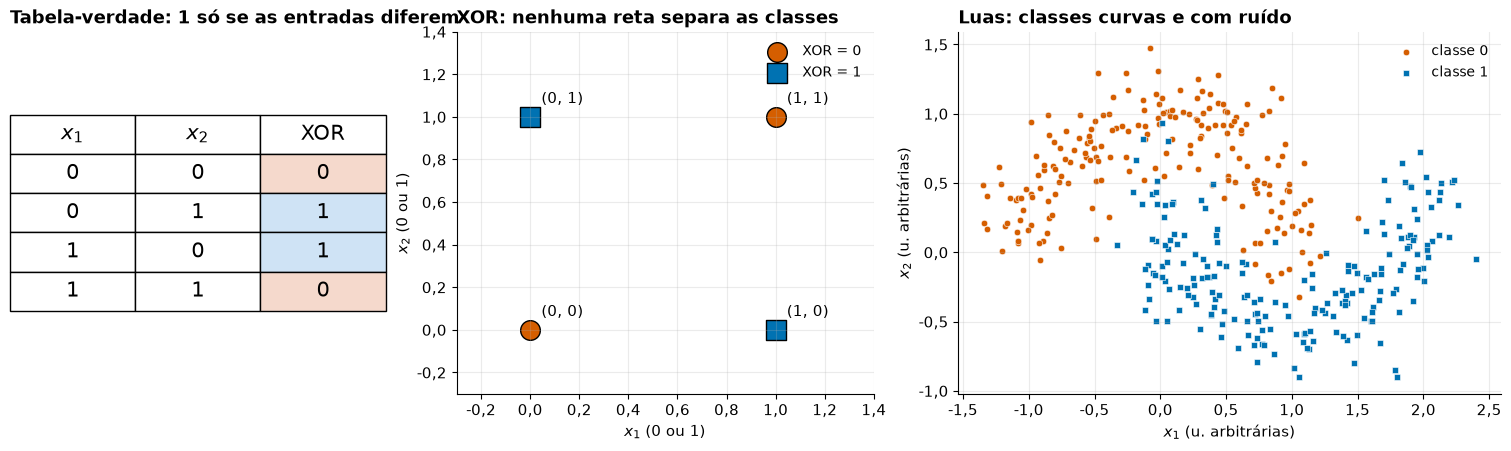

In [2]:
import json
import platform
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, load_digits
from sklearn.model_selection import train_test_split

from src.plotting import apply_style, PALETTE, CYCLE, MARKERS, save_fig, plot_decision_boundary, plot_history
from src.nn_numpy import sigmoid, step, bce_loss, train_perceptron, MLP, gradient_check

apply_style()
FIG = ROOT / "assets" / "figures"

# 🖌️ Auxiliar de gráficos: números à portuguesa (vírgula decimal, espaço nos milhares) e letra ≥ 10 pt
import re
import matplotlib as mpl
from matplotlib.ticker import FuncFormatter
from src.plotting import fmt_pt


def _decimals(axis):
    """Casas decimais necessárias para os valores dos ticks (0 a 3; em escala log, as que o menor tick pede)."""
    locs = np.asarray(axis.get_majorticklocs(), dtype=float)
    if axis.get_scale() == "log":
        locs = np.abs(locs[locs != 0])
        return int(min(4, max(0, np.ceil(-np.log10(locs.min()))))) if locs.size else 0
    for d in range(4):
        if np.allclose(locs, np.round(locs, d), atol=1e-9):
            return d
    return 3


def finish(fig, path=None):
    """Formata os números à portuguesa, garante letra >= 10 pt e (opcionalmente) guarda a figura."""
    for ax in fig.axes:
        for axis in (ax.xaxis, ax.yaxis):
            if type(axis.get_major_formatter()).__name__ in ("StrCategoryFormatter", "FixedFormatter", "NullFormatter"):
                continue
            axis.set_major_formatter(FuncFormatter(lambda v, _, a=axis: fmt_pt(v, _decimals(a))))
    for text in fig.findobj(mpl.text.Text):
        s = text.get_text()
        if re.search(r"\d\.\d", s):
            text.set_text(re.sub(r"(\d)\.(\d)", r"\1,\2", s))
        if text.get_fontsize() < 10:
            text.set_fontsize(10)
    if path is not None:
        save_fig(fig, path)


_show = plt.show


def _show_pt(*args, **kwargs):
    for num in plt.get_fignums():
        finish(plt.figure(num))
    return _show(*args, **kwargs)


plt.show = _show_pt


X_gate = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
Y_GATES = {"AND": np.array([0, 0, 0, 1.]), "OR": np.array([0, 1, 1, 1.]), "XOR": np.array([0, 1, 1, 0.])}
X_moons, y_moons = make_moons(n_samples=400, noise=0.2, random_state=0)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [0.9, 1, 1.3]}, layout="constrained")
# 1) tabela-verdade do XOR, desenhada
axes[0].axis("off")
table = axes[0].table(cellText=[["0", "0", "0"], ["0", "1", "1"], ["1", "0", "1"], ["1", "1", "0"]],
                      colLabels=["$x_1$", "$x_2$", "XOR"], loc="center", cellLoc="center")
table.auto_set_font_size(False); table.set_fontsize(15); table.scale(1, 2.2)
for r in range(1, 5):
    table[r, 2].set_facecolor("#cfe3f5" if r in (2, 3) else "#f5d9cc")
axes[0].set_title("Tabela-verdade: 1 só se as entradas diferem")
# 2) os mesmos 4 pontos no plano
for cls, marker, colour in ((0, "o", PALETTE["red"]), (1, "s", PALETTE["blue"])):
    m = Y_GATES["XOR"] == cls
    axes[1].scatter(X_gate[m, 0], X_gate[m, 1], marker=marker, s=200, color=colour, edgecolor="black", label=f"XOR = {cls}")
    m = y_moons == cls
    axes[2].scatter(X_moons[m, 0], X_moons[m, 1], marker=marker, s=22, color=colour, edgecolor="white", linewidth=0.4,
                    label=f"classe {cls}")
for (x1, x2), y in zip(X_gate, Y_GATES["XOR"]):
    axes[1].annotate(f"({int(x1)}, {int(x2)})", (x1, x2), xytext=(8, 10), textcoords="offset points", fontsize=11)
axes[1].set(title="XOR: nenhuma reta separa as classes", xlabel="$x_1$ (0 ou 1)", ylabel="$x_2$ (0 ou 1)", xlim=(-0.3, 1.4), ylim=(-0.3, 1.4))
axes[2].set(title="Luas: classes curvas e com ruído", xlabel="$x_1$ (u. arbitrárias)", ylabel="$x_2$ (u. arbitrárias)")
for ax in axes[1:]: ax.legend(fontsize=10)
finish(fig, FIG / "04_problems.png"); plt.show()

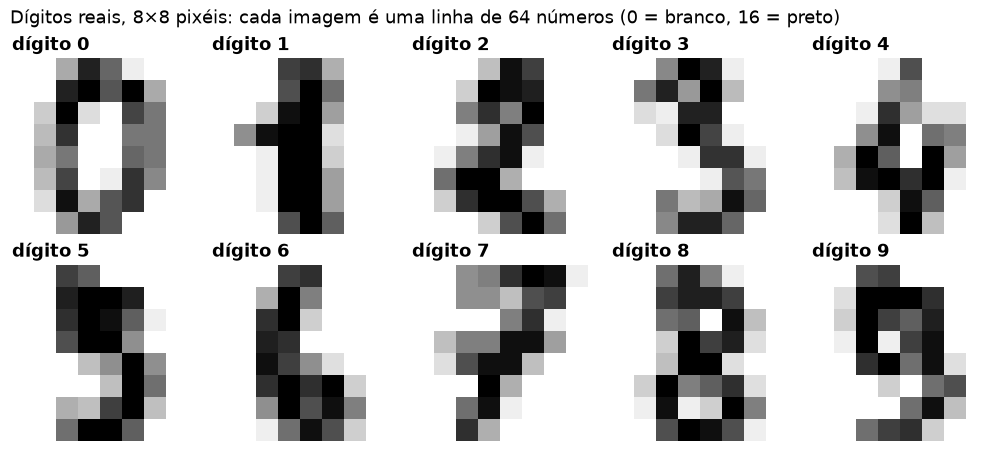

imagens: (1797, 8, 8) | como tabela: (1797, 64) | classes: [0 1 2 3 4 5 6 7 8 9]


In [3]:
digits = load_digits()
fig, axes = plt.subplots(2, 5, figsize=(10, 4.4), layout="constrained")
for d, ax in enumerate(axes.ravel()):
    ax.imshow(digits.images[np.flatnonzero(digits.target == d)[0]], cmap="gray_r"); ax.set_title(f"dígito {d}"); ax.axis("off")
fig.suptitle("Dígitos reais, 8×8 pixéis: cada imagem é uma linha de 64 números (0 = branco, 16 = preto)", x=0.01, ha="left")
finish(fig, FIG / "04_digits_samples.png"); plt.show()
print("imagens:", digits.images.shape, "| como tabela:", digits.data.shape, "| classes:", np.unique(digits.target))

### 💬 Discussão — Porque é que o XOR é difícil?

Desenha com o dedo uma reta que ponha (0,0) e (1,1) de um lado e (0,1) e (1,0) do outro. O que concluis? Que **truque** geométrico resolveria o problema?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

Não existe tal reta: o XOR não é linearmente separável. A solução geométrica é **deformar o espaço** antes de separar: duas retas (uma por neurónio escondido) criam duas novas *features* e, nesse novo espaço, uma reta basta. É exatamente o que uma camada escondida com não linearidade faz, e o que o perceptrão sem camada escondida não consegue (vais ver 4 erros por época, para sempre).
</details>

<a id="sec-3"></a>

# 3. 🤖 Modeling (modelação) · Parte 1 — NumPy puro

## 🧠 Como funciona: o perceptrão (um neurónio)

**Ideia simples.** Um neurónio é uma **votação ponderada**: cada entrada dá o seu "voto" multiplicado por um peso (a importância dessa entrada), somam-se os votos mais um *bias* (um ponto de partida), e se o total passar de zero o neurónio "dispara" (saída 1), senão fica a 0. É o que se chama **degrau** (*step*).

**Passos:** (1) $z = w_1x_1 + w_2x_2 + b$; (2) $\hat y = 1$ se $z \ge 0$, senão $0$; (3) **aprender:** se errou, corrige os pesos um bocadinho na direção do exemplo.

**Analogia:** decidir se vais à praia: o sol pesa muito (+), o frio pesa (−), o trânsito pouco; somas e decides.

**Limite:** é uma **reta** no plano (os pontos com $z=0$). Só separa classes que uma reta consiga separar.

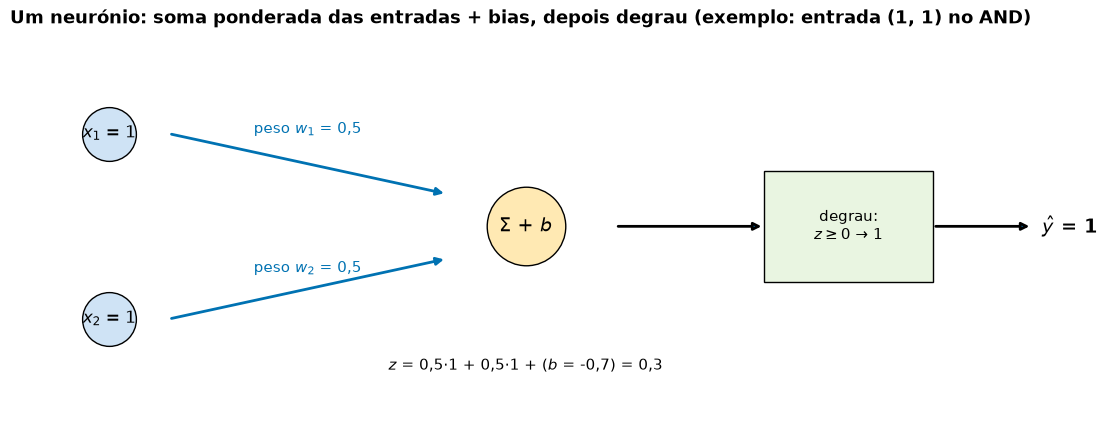

In [4]:
# Mecanismo: um neurónio com valores concretos (AND com pesos escolhidos à mão)
fig, ax = plt.subplots(figsize=(11, 4.2), layout="constrained"); ax.axis("off"); ax.set(xlim=(0, 11), ylim=(0, 4.2))
w1, w2, b0, x1v, x2v = 0.5, 0.5, -0.7, 1, 1
z = w1 * x1v + w2 * x2v + b0
for y, name, val in ((3.1, "$x_1$", x1v), (1.1, "$x_2$", x2v)):
    ax.scatter(1.0, y, s=1500, color="#cfe3f5", edgecolor="black", zorder=3)
    ax.text(1.0, y, f"{name} = {val}", ha="center", va="center", fontsize=12, zorder=4)
for y, wv, name in ((3.1, w1, "$w_1$"), (1.1, w2, "$w_2$")):
    ax.annotate("", xy=(4.4, 2.1 + (y - 2.1) * 0.35), xytext=(1.6, y), arrowprops=dict(arrowstyle="-|>", lw=2, color=PALETTE["blue"]))
    ax.text(3.0, 2.1 + (y - 2.1) * 0.75 + 0.25, f"peso {name} = {fmt_pt(wv, 1)}", ha="center", fontsize=11, color=PALETTE["blue"])
ax.scatter(5.2, 2.1, s=3200, color="#ffe9b3", edgecolor="black", zorder=3)
ax.text(5.2, 2.1, "Σ + $b$", ha="center", va="center", fontsize=14, zorder=4)
ax.text(5.2, 0.55, f"$z$ = 0,5·1 + 0,5·1 + ($b$ = {fmt_pt(b0, 1)}) = {fmt_pt(z, 1)}", ha="center", fontsize=11)
ax.annotate("", xy=(7.6, 2.1), xytext=(6.1, 2.1), arrowprops=dict(arrowstyle="-|>", lw=2))
ax.add_patch(plt.Rectangle((7.6, 1.5), 1.7, 1.2, fc="#e9f5e1", ec="black", zorder=3))
ax.text(8.45, 2.1, "degrau:" + chr(10) + "$z \\geq 0$ → 1", ha="center", va="center", fontsize=11, zorder=4)
ax.annotate("", xy=(10.3, 2.1), xytext=(9.3, 2.1), arrowprops=dict(arrowstyle="-|>", lw=2))
ax.text(10.4, 2.1, f"$\\hat y$ = {int(z >= 0)}", ha="left", va="center", fontsize=14, fontweight="bold")
ax.set_title("Um neurónio: soma ponderada das entradas + bias, depois degrau (exemplo: entrada (1, 1) no AND)")
finish(fig, FIG / "04_perceptron_diagram.png"); plt.show()

## 3.1 O perceptrão (Rosenblatt, 1958)

Um único neurónio: $\hat y = \text{step}(w\cdot x + b)$. A regra de aprendizagem: se errou, move os pesos na direção do exemplo. `train_perceptron` devolve os pesos e o **número de erros por época**.

AND  erros na última época: 0 | previsões: [0 0 0 1] (alvo [0 0 0 1])
OR   erros na última época: 0 | previsões: [0 1 1 1] (alvo [0 1 1 1])
XOR  erros na última época: 4 | previsões: [1 0 0 0] (alvo [0 1 1 0])


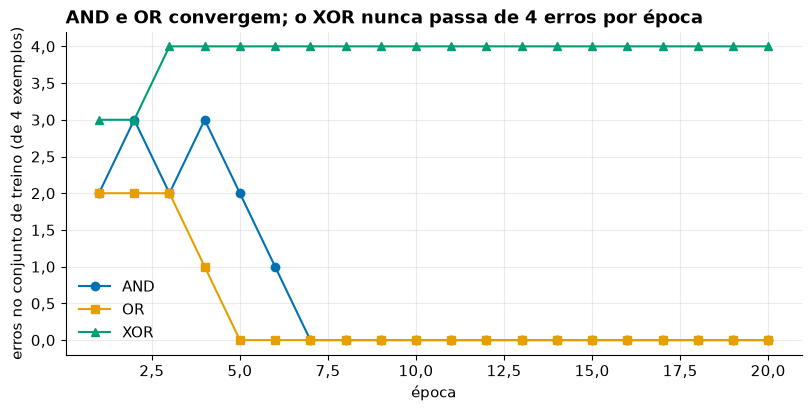

In [5]:
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
for (name, y), marker in zip(Y_GATES.items(), MARKERS):
    w, b, errors = train_perceptron(X_gate, y, lr=0.1, epochs=20, seed=0)
    pred = step(X_gate @ w + b)
    print(f"{name:<4} erros na última época: {errors[-1]} | previsões: {pred.astype(int)} (alvo {y.astype(int)})")
    ax.plot(range(1, 21), errors, marker=marker, label=name)
ax.set(title="AND e OR convergem; o XOR nunca passa de 4 erros por época", xlabel="época", ylabel="erros no conjunto de treino (de 4 exemplos)")
ax.legend(); finish(fig, FIG / "04_perceptron_errors.png"); plt.show()

AND e OR são linearmente separáveis e o perceptrão converge a 0 erros. No XOR, os erros oscilam (4 por época no fim): é o resultado que Minsky e Papert (1969) usaram para argumentar contra os perceptrões de uma só camada.

## 3.2 O MLP: *forward* com *shapes* e números

A rede de `src.nn_numpy.MLP` tem uma camada escondida (*tanh*) e uma saída sigmoide. Com $n$ exemplos, $d$ *features* e $h$ neurónios escondidos:

$$z_1 = X W_1 + b_1,\quad a_1 = \tanh(z_1),\quad z_2 = a_1 W_2 + b_2,\quad \hat y = \sigma(z_2)$$

| Símbolo | *Shape* | Significado |
|---|---|---|
| $X$ | $(n, d)$ | um exemplo por linha |
| $W_1$, $b_1$ | $(d, h)$, $(h,)$ | pesos e *bias* da camada escondida |
| $z_1$, $a_1$ | $(n, h)$ | pré-ativação e ativação |
| $W_2$, $b_2$ | $(h, 1)$, $(1,)$ | camada de saída |
| $\hat y$ | $(n,)$ | probabilidade da classe 1 |

## 🧠 Como funciona: o MLP (várias camadas)

**Ideia simples.** Se um neurónio só traça uma reta, **vários neurónios em camadas** traçam várias retas e combinam-nas. Cada neurónio da camada escondida aprende a responder a uma pergunta simples ("estou acima desta reta?"); o neurónio de saída combina as respostas. É assim que se resolve o XOR: uma reta pergunta "algum x é 1?", outra "ambos são 1?", e a saída diz "o primeiro sim e o segundo não".

**Passos (forward):** entrada → camada escondida (soma ponderada + *tanh*, uma ativação suave entre −1 e 1) → saída (soma ponderada + sigmoide, que dá uma probabilidade entre 0 e 1).

**Cuidados:** sem a ativação não linear, várias camadas seriam equivalentes a uma só (continuaria a ser uma reta).

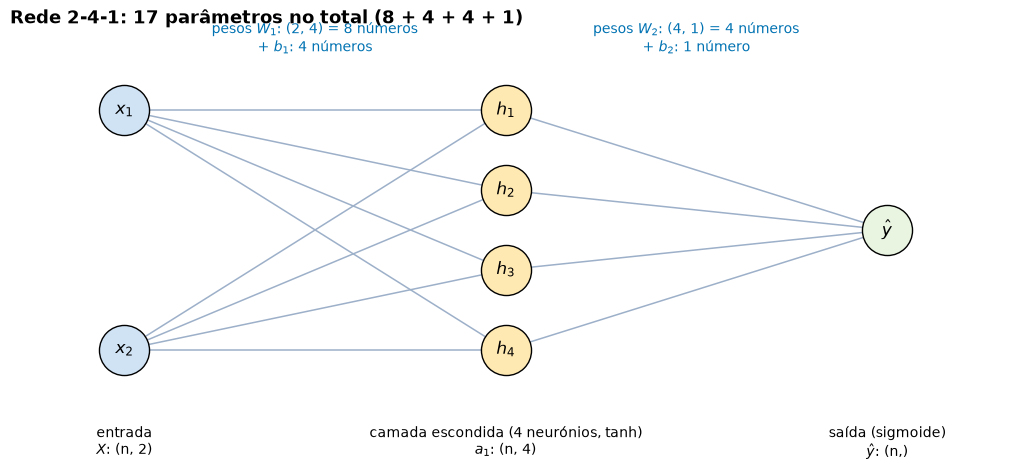

In [6]:
# Mecanismo: o diagrama da rede 2 → 4 → 1 que vamos usar (cada linha é um peso a aprender)
fig, ax = plt.subplots(figsize=(10, 4.6), layout="constrained"); ax.axis("off"); ax.set(xlim=(-0.15, 1.15), ylim=(-0.12, 1.08))
sizes, titles = (2, 4, 1), ("entrada" + chr(10) + "$X$: (n, 2)", "camada escondida (4 neurónios, tanh)" + chr(10) + "$a_1$: (n, 4)", "saída (sigmoide)" + chr(10) + "$\\hat y$: (n,)")
coords = [[(x, y) for y in (np.linspace(0.85, 0.15, n) if n > 1 else [0.5])] for x, n in zip((0.0, 0.5, 1.0), sizes)]
for left, right in zip(coords[:-1], coords[1:]):
    for p in left:
        for q in right:
            ax.plot([p[0], q[0]], [p[1], q[1]], color="#9db0c9", lw=1.1, zorder=1)
labels = (["$x_1$", "$x_2$"], ["$h_1$", "$h_2$", "$h_3$", "$h_4$"], ["$\\hat y$"])
for layer, lab, colour in zip(coords, labels, ("#cfe3f5", "#ffe9b3", "#e9f5e1")):
    for (x, y), t in zip(layer, lab):
        ax.scatter(x, y, s=1300, color=colour, edgecolor="black", zorder=3)
        ax.text(x, y, t, ha="center", va="center", fontsize=12, zorder=4)
for x, t in zip((0.0, 0.5, 1.0), titles):
    ax.text(x, -0.07, t, ha="center", va="top", fontsize=10)
ax.text(0.25, 1.02, "pesos $W_1$: (2, 4) = 8 números" + chr(10) + "+ $b_1$: 4 números", ha="center", fontsize=10, color=PALETTE["blue"])
ax.text(0.75, 1.02, "pesos $W_2$: (4, 1) = 4 números" + chr(10) + "+ $b_2$: 1 número", ha="center", fontsize=10, color=PALETTE["blue"])
ax.set_title("Rede 2-4-1: 17 parâmetros no total (8 + 4 + 4 + 1)")
finish(fig, FIG / "04_mlp_diagram.png"); plt.show()

In [7]:
xor = MLP(n_in=2, n_hidden=4, seed=0)           # pesos iniciais aleatórios (Xavier), seed fixa
for name, p in xor.params.items():
    print(f"{name}: shape {p.shape}")
print("W1 =\n", xor.params["W1"].round(3))
print("W2 (transposta) =", xor.params["W2"].ravel().round(3))

W1: shape (2, 4)
b1: shape (4,)
W2: shape (4, 1)
b2: shape (1,)
W1 =
 [[ 0.089 -0.093  0.453  0.074]
 [-0.379  0.256  0.922  0.67 ]]
W2 (transposta) = [-0.352 -0.633 -0.312  0.021]


In [8]:
# Forward à mão para UM exemplo, x = (0, 1), passo a passo
x = X_gate[1:2]                                  # shape (1, 2)
z1 = x @ xor.params["W1"] + xor.params["b1"]     # (1, 2) @ (2, 4) -> (1, 4)
a1 = np.tanh(z1)                                 # (1, 4), valores em (-1, 1)
z2 = a1 @ xor.params["W2"] + xor.params["b2"]    # (1, 4) @ (4, 1) -> (1, 1)
y_hat = sigmoid(z2)                              # probabilidade da classe 1

print("z1 =", z1.round(3), "\na1 =", a1.round(3), "\nz2 =", z2.round(3), "\nŷ  =", y_hat.round(3))
print("igual ao método forward do MLP?", np.allclose(y_hat.ravel(), xor.forward(x)[0]))
print("sem treino, ŷ ≈ 0,5 para tudo; o alvo para (0,1) é 1")

z1 = [[-0.379  0.256  0.922  0.67 ]] 
a1 = [[-0.362  0.25   0.727  0.585]] 
z2 = [[-0.246]] 
ŷ  = [[0.439]]
igual ao método forward do MLP? True
sem treino, ŷ ≈ 0,5 para tudo; o alvo para (0,1) é 1


## 3.3 A *loss* e o *backprop*

Para classificação binária usamos a *binary cross-entropy*: $\mathcal L = -\tfrac1n\sum \big[y\log\hat y + (1-y)\log(1-\hat y)\big]$. Penaliza muito quem está confiante e errado.

O **backprop** é a regra da cadeia, da *loss* para trás, camada a camada:

1. $\partial\mathcal L/\partial z_2 = (\hat y - y)/n$ (a combinação sigmoide + BCE simplifica);
2. $\partial\mathcal L/\partial W_2 = a_1^\top\,\partial\mathcal L/\partial z_2$, e $\partial\mathcal L/\partial b_2$ é a soma;
3. $\partial\mathcal L/\partial a_1 = \partial\mathcal L/\partial z_2\;W_2^\top$;
4. $\partial\mathcal L/\partial z_1 = \partial\mathcal L/\partial a_1 \odot (1 - a_1^2)$, porque $\tanh'(z)=1-\tanh^2(z)$;
5. $\partial\mathcal L/\partial W_1 = X^\top\,\partial\mathcal L/\partial z_1$, e $\partial\mathcal L/\partial b_1$ é a soma.

Depois, descida do gradiente: $W \leftarrow W - \eta\,\partial\mathcal L/\partial W$, com $\eta$ o *learning rate*.

In [9]:
y_xor = Y_GATES["XOR"]
y_hat, cache = xor.forward(X_gate)
print(f"loss inicial = {bce_loss(y_xor, y_hat):.4f}   (ln 2 = {np.log(2):.4f}: equivale a chutar 50/50)")

# Backprop escrito linha a linha, com as shapes
n = len(y_xor)
dz2 = (y_hat - y_xor).reshape(-1, 1) / n             # (4, 1)
dW2 = cache["a1"].T @ dz2                            # (4, 4).T @ (4, 1) -> (4, 1)
db2 = dz2.sum(axis=0)                                # (1,)
da1 = dz2 @ xor.params["W2"].T                       # (4, 1) @ (1, 4) -> (4, 4)
dz1 = da1 * (1 - cache["a1"] ** 2)                   # (4, 4)
dW1 = X_gate.T @ dz1                                 # (2, 4)
db1 = dz1.sum(axis=0)                                # (4,)

grads = xor.backward(y_xor, cache)
mine = {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}
print("o meu backprop = backward() do MLP?", all(np.allclose(mine[k], grads[k]) for k in mine))
print("shapes dos gradientes:", {k: v.shape for k, v in grads.items()})

loss inicial = 0.7081   (ln 2 = 0.6931: equivale a chutar 50/50)
o meu backprop = backward() do MLP? True
shapes dos gradientes: {'W1': (2, 4), 'b1': (4,), 'W2': (4, 1), 'b2': (1,)}


### 🧠 Como funciona: descida do gradiente

**Ideia simples.** Imagina que estás num vale com nevoeiro e queres chegar ao fundo: sentes a inclinação do chão (o **gradiente**) e dás um passo para baixo. Repetes. O **tamanho do passo** é o *learning rate* $\eta$.

**Passos:** (1) calcular a *loss* $L$; (2) calcular o gradiente $\partial L/\partial w$ (a inclinação); (3) atualizar $w \leftarrow w - \eta\,\partial L/\partial w$; (4) repetir. Abaixo, o caso mais simples: **um só peso** e uma *loss* em forma de taça, $L(w) = (w-3)^2 + 1$.

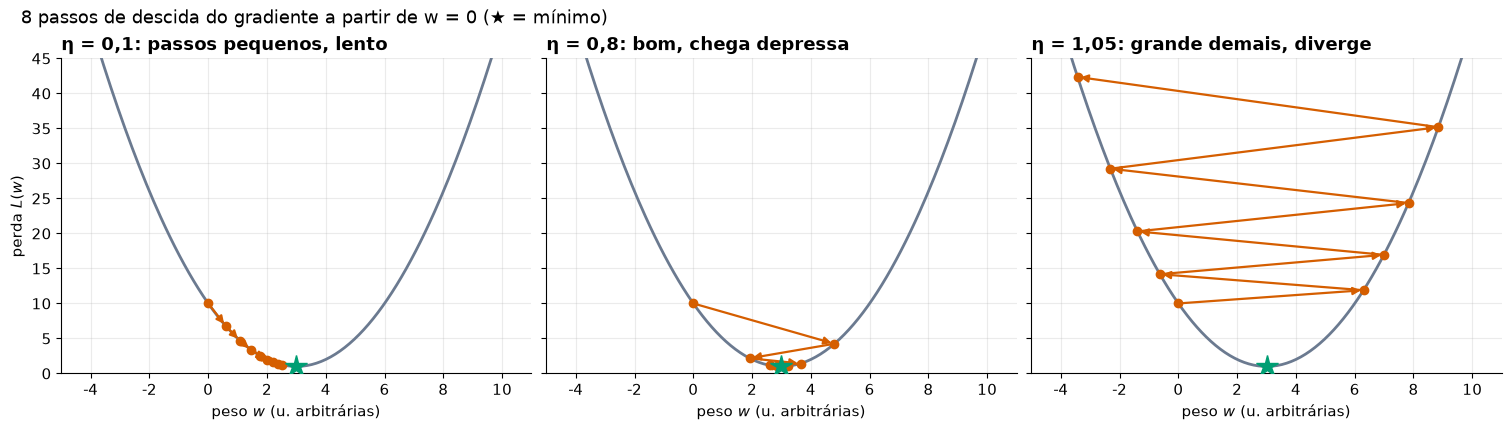

In [10]:
w_axis = np.linspace(-5, 11, 200)
L = lambda w: (w - 3) ** 2 + 1
dL = lambda w: 2 * (w - 3)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True, layout="constrained")
for ax, (eta, title) in zip(axes, ((0.1, "η = 0,1: passos pequenos, lento"), (0.8, "η = 0,8: bom, chega depressa"),
                                    (1.05, "η = 1,05: grande demais, diverge"))):
    ax.plot(w_axis, L(w_axis), color=PALETTE["grey"], lw=2)
    ws = [0.0]
    for _ in range(8):
        ws.append(ws[-1] - eta * dL(ws[-1]))
    ws = np.array(ws)
    for a, b in zip(ws[:-1], ws[1:]):
        ax.annotate("", xy=(b, L(b)), xytext=(a, L(a)), arrowprops=dict(arrowstyle="-|>", color=PALETTE["red"], lw=1.6))
    ax.plot(ws, L(ws), "o", color=PALETTE["red"], ms=6)
    ax.plot(3, 1, marker="*", ms=16, color=PALETTE["green"], zorder=5)
    ax.set(title=title, xlabel="peso $w$ (u. arbitrárias)", ylim=(0, 45), xlim=(-5, 11))
axes[0].set_ylabel("perda $L(w)$")
fig.suptitle("8 passos de descida do gradiente a partir de w = 0 (★ = mínimo)", x=0.01, ha="left")
finish(fig, FIG / "04_gradient_descent.png"); plt.show()

## 3.4 *Gradient check*: como saber que o backprop está certo?

Compara-se o gradiente analítico com uma estimativa numérica (diferenças centrais): $\dfrac{\mathcal L(w+\epsilon)-\mathcal L(w-\epsilon)}{2\epsilon}$. Uma diferença relativa abaixo de ~$10^{-6}$ confirma o cálculo.

In [11]:
rel_diff = gradient_check(MLP(2, 4, seed=0), X_gate, y_xor)
print(f"diferença relativa máxima backprop vs numérico = {rel_diff:.1e}")
print("backprop correto?", rel_diff < 1e-6)

diferença relativa máxima backprop vs numérico = 3.2e-09
backprop correto? True


> ⚠️ **Cuidado:** o *gradient check* é lento (duas *forwards* por parâmetro) e serve só para **depurar**. No treino usa-se sempre o gradiente analítico (ou o autograd).

### 💬 Discussão — Porque confiar na derivada numérica?

O gradient check dá uma diferença de ≈ 3·10⁻⁹. Se te desse 0,3, o que suspeitarias? E porque não usar a derivada numérica para treinar?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

Um valor tão grande indicaria **erro no backprop** (por exemplo, esquecer um fator $1/n$ ou usar $\tanh'$ errada). Com 2·10⁻⁹ o cálculo está correto. A derivada numérica custa duas *forwards* **por parâmetro**: numa rede com milhões de pesos seria impraticável, enquanto o backprop calcula todos os gradientes com um único passo para trás.
</details>

## 3.5 Treinar no XOR: a fronteira nasce da loss

Treino *full-batch* (todos os exemplos por passo): `lr=0.5`, 2000 épocas. Guardamos *snapshots* dos pesos para ver a fronteira de decisão a evoluir.

In [12]:
def model_from(params, n_in=2, n_hidden=4):
    """Recria um MLP com os pesos de um snapshot (para desenhar a fronteira nesse momento)."""
    m = MLP(n_in, n_hidden, seed=0)
    m.params = {k: v.copy() for k, v in params.items()}
    return m

xor = MLP(2, 4, seed=0)
start = {k: v.copy() for k, v in xor.params.items()}
hist_xor = xor.fit(X_gate, y_xor, lr=0.5, epochs=2000, snapshots=(100, 500, 2000))
snaps = [(0, start)] + hist_xor["snapshots"]
print(f"loss: {hist_xor['loss'][0]:.3f} (época 1) -> {hist_xor['loss'][-1]:.4f} (época 2000)")
print("saídas finais:", xor.predict_proba(X_gate).round(3), "| alvo:", y_xor.astype(int))

loss: 0.708 (época 1) -> 0.0022 (época 2000)
saídas finais: [0.    0.997 0.997 0.003] | alvo: [0 1 1 0]


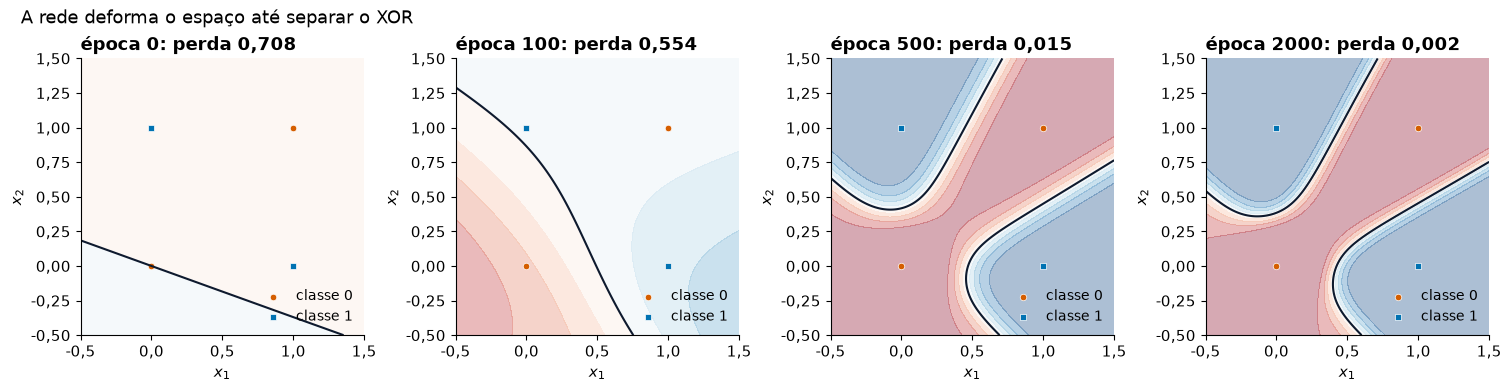

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), layout="constrained")
for ax, (ep, params) in zip(axes, snaps):
    m = model_from(params)
    plot_decision_boundary(m.predict_proba, X_gate, y_xor, ax=ax, title=f"época {ep}: perda {m.loss(X_gate, y_xor):.3f}")
fig.suptitle("A rede deforma o espaço até separar o XOR", x=0.01, ha="left")
finish(fig, FIG / "04_xor_snapshots.png"); plt.show()

## 3.6 Luas: uma fronteira curva

`MLP(2, 8)`, `lr=0.5`, 3000 épocas, em `make_moons(400, noise=0.2, random_state=0)`.

In [14]:
y_m = y_moons.astype(float)
moons = MLP(2, 8, seed=0)
start_m = {k: v.copy() for k, v in moons.params.items()}
hist_m = moons.fit(X_moons, y_m, lr=0.5, epochs=3000, snapshots=(100, 500, 3000))
acc = (moons.predict(X_moons) == y_moons).mean()
print(f"loss final = {hist_m['loss'][-1]:.3f} | accuracy no treino = {acc:.3f}")

loss final = 0.091 | accuracy no treino = 0.965


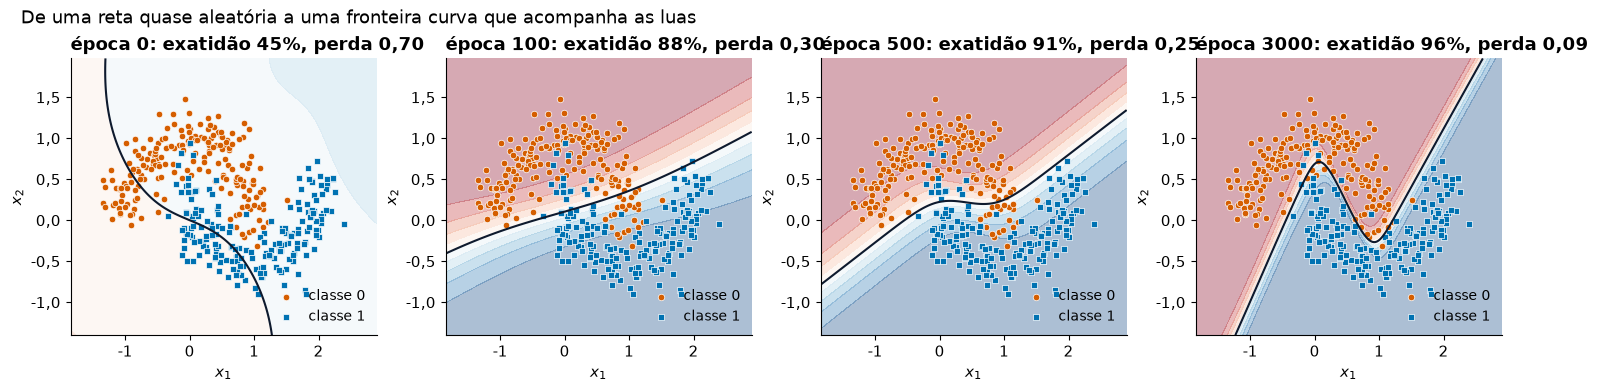

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), layout="constrained")
for ax, (ep, params) in zip(axes, [(0, start_m)] + hist_m["snapshots"]):
    m = model_from(params, 2, 8)
    a = (m.predict(X_moons) == y_moons).mean()
    plot_decision_boundary(m.predict_proba, X_moons, y_moons, ax=ax, title=f"época {ep}: exatidão {a:.0%}, perda {m.loss(X_moons, y_m):.2f}")
fig.suptitle("De uma reta quase aleatória a uma fronteira curva que acompanha as luas", x=0.01, ha="left")
finish(fig, FIG / "04_moons_snapshots.png"); plt.show()

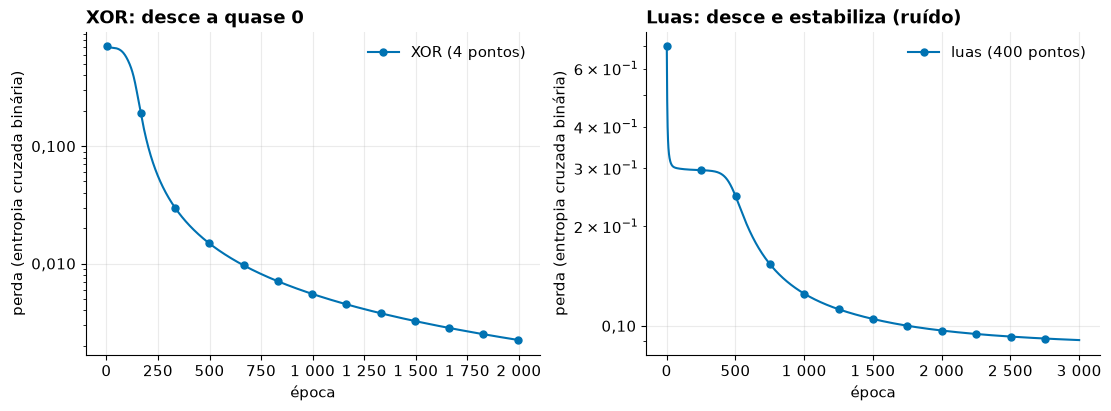

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
plot_history({"XOR (4 pontos)": hist_xor["loss"]}, ylabel="perda (entropia cruzada binária)", title="XOR: desce a quase 0", ax=axes[0])
plot_history({"luas (400 pontos)": hist_m["loss"]}, ylabel="perda (entropia cruzada binária)", title="Luas: desce e estabiliza (ruído)", ax=axes[1])
axes[0].set_yscale("log"); axes[1].set_yscale("log")
finish(fig, FIG / "04_numpy_loss.png"); plt.show()

### 💬 Discussão — Modelação: quantos neurónios escondidos?

Com 8 neurónios a rede acerta ≈ 96,5 % nos pontos de treino das luas. O que esperas se usares 1 neurónio escondido? E 100? Qual dos números é o que interessa a quem vai usar o modelo?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

Com 1 neurónio escondido a fronteira é praticamente uma reta suave (ver exercício 2) e a *accuracy* de treino fica em ≈ 88 %, o mesmo que uma regressão logística (87,5 %). Com muitos neurónios a rede consegue ajustar o ruído: a *accuracy* **de treino** sobe, mas é a **de dados novos** que interessa (secção 6). A *accuracy* de treino de 96,5 % não diz nada sobre generalização.
</details>

## 3.7 O *learning rate*: pequeno demais é lento, grande demais é instável

Mesmos dados e rede, só muda $\eta$.

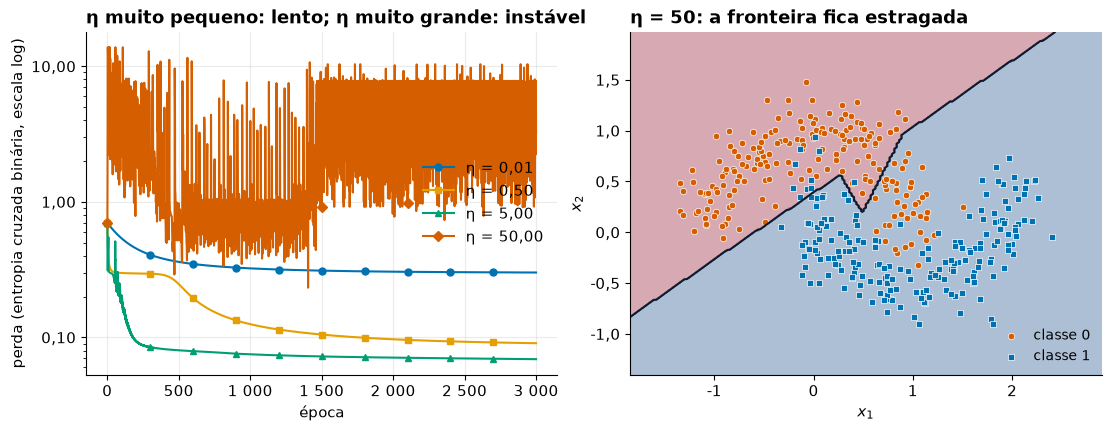

,loss final,accuracy treino
η,,
0.01,0.301,0.880
0.50,0.091,0.965
5.00,0.069,0.970
50.00,3.226,0.868


In [17]:
lrs = [0.01, 0.5, 5.0, 50.0]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
rows = []
for lr, marker in zip(lrs, MARKERS):
    m = MLP(2, 8, seed=0)
    h = m.fit(X_moons, y_m, lr=lr, epochs=3000)
    axes[0].plot(range(1, 3001), h["loss"], marker=marker, markevery=300, ms=5, label=f"η = {fmt_pt(lr, 2)}")
    rows.append({"η": lr, "loss final": round(h["loss"][-1], 3), "accuracy treino": round((m.predict(X_moons) == y_moons).mean(), 3)})
axes[0].set(yscale="log", title="η muito pequeno: lento; η muito grande: instável", xlabel="época", ylabel="perda (entropia cruzada binária, escala log)")
axes[0].legend()
m = MLP(2, 8, seed=0); m.fit(X_moons, y_m, lr=50.0, epochs=3000)
plot_decision_boundary(m.predict_proba, X_moons, y_moons, ax=axes[1], title="η = 50: a fronteira fica estragada")
finish(fig, FIG / "04_learning_rate.png"); plt.show()
pd.DataFrame(rows).set_index("η")

Com $\eta = 0{,}01$, passadas 3000 épocas a rede ainda está longe (loss ≈ 0,30). Com $\eta=0{,}5$ e $\eta=5$ chega a loss ≈ 0,09 e 0,07. Com $\eta=50$ os passos "saltam por cima" do mínimo: a *loss* **sobe** (≈ 3) e oscila, e a *accuracy* cai.

> 💡 **Dica:** não existe um $\eta$ universal; é o hiperparâmetro mais importante do treino. Na prática começa-se com valores conhecidos (por exemplo, 1e-3 no Adam) e ajusta-se olhando para a curva da *loss*.

### 💬 Discussão — Ler uma curva de loss

Mostram-te uma curva de *loss* que sobe e desce de forma errática. E outra que desce muito devagar e ainda não estabilizou ao fim do treino. Que diagnóstico e que ação para cada uma?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

Errática/a subir = $\eta$ demasiado grande (o caso $\eta=50$ acima): **reduzir** o *learning rate*. Descida lenta que ainda não estabilizou = $\eta$ pequeno ($\eta=0{,}01$: loss ≈ 0,30 ao fim de 3000 épocas) ou poucas épocas: **aumentar** $\eta$ ou treinar mais. Em ambos os casos, o primeiro passo é desenhar a curva (e não só olhar para o último valor).
</details>

<a id="sec-4"></a>

# 4. 🧹 Data Preparation (preparação dos dados) para o PyTorch

Na parte 2 passamos a um problema real: `load_digits` (1797 imagens 8×8 de dígitos, 10 classes). Preparar para uma rede neuronal exige:

1. **Escalar** as entradas: os pixéis vão de 0 a 16; dividimos por 16 para ficarem em [0, 1] (redes treinam mais depressa com entradas pequenas e centradas);
2. **Separar treino e validação** *antes* de olhar para a validação (estratificado: cada classe com a mesma proporção);
3. Converter para **tensores** (`float32` para as entradas, `int64` para as classes).

Para tornar o *overfitting* bem visível, treinamos com poucos exemplos (300) e validamos com 360 imagens que a rede nunca vê durante o treino.

In [18]:
import torch
from torch import nn

SEED = 42
torch.manual_seed(SEED)
print("PyTorch", torch.__version__, "| GPU disponível:", torch.cuda.is_available())

digits = load_digits()
X_all = (digits.data / 16.0).astype("float32")           # pixéis 0..16 -> 0..1
y_all = digits.target.astype("int64")
X_tr_full, X_va, y_tr_full, y_va = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=SEED)
X_tr, y_tr = X_tr_full[:300], y_tr_full[:300]            # poucos dados para o overfitting ser visível

Xtr, ytr, Xva, yva = (torch.from_numpy(a) for a in (X_tr, y_tr, X_va, y_va))
print("treino:", tuple(Xtr.shape), Xtr.dtype, "| validação:", tuple(Xva.shape), "| classes no treino:", np.bincount(y_tr))

PyTorch 2.11.0+cu128 | GPU disponível: True
treino: (300, 64) torch.float32 | validação: (360, 64) | classes no treino: [34 42 29 35 35 21 26 24 27 27]


<a id="sec-5"></a>

# 5. 🤖 Modeling · Parte 2 — PyTorch

## 5.1 Tensores e autograd

Um **tensor** é um *array* multidimensional (como o `np.ndarray`) que pode viver na GPU e **guardar o histórico das operações** para calcular gradientes automaticamente (*autograd*). `loss.backward()` percorre esse histórico ao contrário: é o backprop da secção 3, sem o escrevermos.

Um exemplo minúsculo: um só neurónio sigmoide, com $z = wx + b$, $\hat y=\sigma(z)$ e BCE. A derivada manual é $\partial\mathcal L/\partial w = (\hat y - y)\,x$.

In [19]:
x_t, y_t = torch.tensor(2.0), torch.tensor(1.0)
w = torch.tensor(0.3, requires_grad=True)
b = torch.tensor(-0.1, requires_grad=True)

y_hat_t = torch.sigmoid(w * x_t + b)
loss_t = -(y_t * torch.log(y_hat_t) + (1 - y_t) * torch.log(1 - y_hat_t))
loss_t.backward()                                    # autograd preenche w.grad e b.grad

manual_dw = (y_hat_t.detach() - y_t) * x_t           # fórmula à mão
manual_db = (y_hat_t.detach() - y_t)
print(f"autograd: dL/dw = {w.grad.item():.6f}, dL/db = {b.grad.item():.6f}")
print(f"à mão   : dL/dw = {manual_dw.item():.6f}, dL/db = {manual_db.item():.6f}")

autograd: dL/dw = -0.755081, dL/db = -0.377541
à mão   : dL/dw = -0.755081, dL/db = -0.377541


Agora o teste a sério: os **mesmos pesos** do `MLP` NumPy, passados para tensores, e o gradiente do PyTorch comparado com o nosso `backward`.

In [20]:
ref = MLP(2, 4, seed=0)
p = {k: torch.tensor(v, dtype=torch.float64, requires_grad=True) for k, v in ref.params.items()}
Xt, yt = torch.tensor(X_gate), torch.tensor(y_xor)
out = torch.sigmoid(torch.tanh(Xt @ p["W1"] + p["b1"]) @ p["W2"] + p["b2"]).squeeze(1)
torch.nn.functional.binary_cross_entropy(out, yt).backward()

ours = ref.backward(y_xor, ref.forward(X_gate)[1])
for name in ours:
    print(f"{name}: máx |autograd − NumPy| = {np.abs(p[name].grad.numpy() - ours[name]).max():.1e}")

W1: máx |autograd − NumPy| = 0.0e+00
b1: máx |autograd − NumPy| = 0.0e+00
W2: máx |autograd − NumPy| = 1.2e-17
b2: máx |autograd − NumPy| = 0.0e+00


## 5.2 `nn.Module` e o *loop* de treino

Uma rede em PyTorch é uma subclasse de `nn.Module`: o `__init__` declara as camadas, o `forward` diz como se ligam. O *loop* de treino repete 4 passos: **forward → loss → backward → atualizar**.

O `Net` abaixo tem 2 camadas escondidas e aceita `dropout` (que desligamos para já).

In [21]:
class Net(nn.Module):
    def __init__(self, n_in=64, n_hidden=256, n_out=10, dropout=0.0):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_in, n_hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(n_hidden, n_hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(n_hidden, n_out),                  # 10 "logits" (sem softmax: a loss já o inclui)
        )

    def forward(self, x):
        return self.layers(x)

net = Net()
n_params = sum(p.numel() for p in net.parameters())
print(net)
print(f"parâmetros: {n_params:,} (para apenas 300 exemplos de treino!)")

Net(
  (layers): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.0, inplace=False)
    (3): Linear(in_features=256, out_features=256, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.0, inplace=False)
    (6): Linear(in_features=256, out_features=10, bias=True)
  )
)
parâmetros: 85,002 (para apenas 300 exemplos de treino!)


In [22]:
def accuracy(logits, y):
    return (logits.argmax(dim=1) == y).float().mean().item()

def train(model, epochs=150, lr=1e-3, weight_decay=0.0, batch_size=32, patience=None, seed=SEED):
    """Loop de treino com AdamW. Devolve o histórico por época (loss e accuracy de treino e validação).

    Com `patience`, faz *early stopping*: para quando a loss de validação não melhora durante `patience`
    épocas e restaura os melhores pesos.
    """
    torch.manual_seed(seed)
    loss_fn = nn.CrossEntropyLoss()
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    hist = {"loss_tr": [], "loss_va": [], "acc_tr": [], "acc_va": []}
    best, best_state, wait = float("inf"), None, 0
    for epoch in range(epochs):
        model.train()
        order = torch.randperm(len(Xtr))
        for i in range(0, len(order), batch_size):          # mini-batches
            idx = order[i:i + batch_size]
            opt.zero_grad()
            loss_fn(model(Xtr[idx]), ytr[idx]).backward()    # forward + loss + backward
            opt.step()                                       # atualizar pesos
        model.eval()
        with torch.no_grad():                                # avaliação: sem gradientes
            out_tr, out_va = model(Xtr), model(Xva)
            hist["loss_tr"].append(loss_fn(out_tr, ytr).item()); hist["loss_va"].append(loss_fn(out_va, yva).item())
            hist["acc_tr"].append(accuracy(out_tr, ytr)); hist["acc_va"].append(accuracy(out_va, yva))
        if patience:
            if hist["loss_va"][-1] < best - 1e-4:
                best, best_state, wait = hist["loss_va"][-1], {k: v.clone() for k, v in model.state_dict().items()}, 0
            else:
                wait += 1
                if wait >= patience:
                    break
    if patience and best_state is not None:
        model.load_state_dict(best_state)
        hist["stopped_at"] = len(hist["loss_va"])
        hist["best_epoch"] = len(hist["loss_va"]) - wait
    return hist

torch.manual_seed(SEED)
t0 = time.perf_counter()
h_base = train(Net())
print(f"treino de 150 épocas em {time.perf_counter() - t0:.1f} s (CPU)")
print(f"época 150: loss treino {h_base['loss_tr'][-1]:.4f} | loss validação {h_base['loss_va'][-1]:.3f} | "
      f"acc treino {h_base['acc_tr'][-1]:.3f} | acc validação {h_base['acc_va'][-1]:.3f}")

treino de 150 épocas em 2.9 s (CPU)
época 150: loss treino 0.0005 | loss validação 0.220 | acc treino 1.000 | acc validação 0.936


<a id="sec-6"></a>

# 6. 📏 Evaluation (avaliação): curvas e regularização

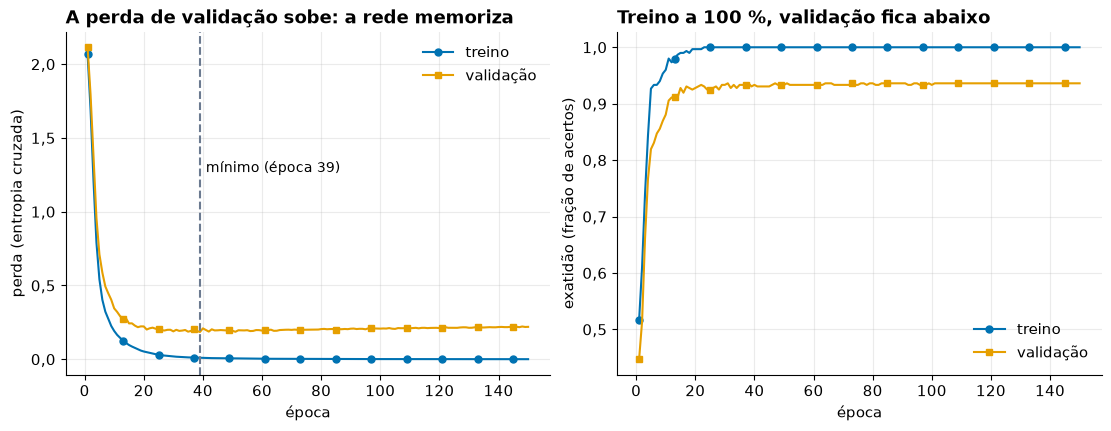

menor loss de validação na época 39; a partir daí piora (0.185 -> 0.220)


In [23]:
best_ep = int(np.argmin(h_base["loss_va"])) + 1
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
plot_history({"treino": h_base["loss_tr"], "validação": h_base["loss_va"]}, ylabel="perda (entropia cruzada)",
             title="A perda de validação sobe: a rede memoriza", ax=axes[0])
axes[0].axvline(best_ep, color=PALETTE["grey"], ls="--"); axes[0].text(best_ep + 2, max(h_base["loss_va"]) * 0.6, f"mínimo (época {best_ep})", fontsize=10)
plot_history({"treino": h_base["acc_tr"], "validação": h_base["acc_va"]}, ylabel="exatidão (fração de acertos)",
             title="Treino a 100 %, validação fica abaixo", ax=axes[1])
finish(fig, FIG / "04_torch_curves.png"); plt.show()
print(f"menor loss de validação na época {best_ep}; a partir daí piora ({h_base['loss_va'][best_ep - 1]:.3f} -> {h_base['loss_va'][-1]:.3f})")

**Overfitting:** a *loss* de treino continua a descer para ≈ 0, mas a de validação **para de descer e volta a subir**. A rede passou a decorar os 300 exemplos em vez de aprender o que distingue os dígitos.

### Três formas de o travar

| Técnica | Ideia |
|---|---|
| ***weight decay*** | penaliza pesos grandes (aqui, via `AdamW(weight_decay=…)`) |
| ***dropout*** | desliga neurónios ao acaso em cada passo de treino: a rede não pode depender de um só |
| ***early stopping*** | pára de treinar quando a *loss* de validação deixa de melhorar e fica com os melhores pesos |

Comparamos com 3 seeds de inicialização (0, 1, 2) para não tirar conclusões de uma só corrida.

In [24]:
configs = {
    "base": dict(model=dict(dropout=0.0), train=dict()),
    "decaimento de pesos 0,1": dict(model=dict(dropout=0.0), train=dict(weight_decay=0.1)),
    "dropout 0,3": dict(model=dict(dropout=0.3), train=dict()),
    "paragem antecipada": dict(model=dict(dropout=0.0), train=dict(patience=15)),
}
results, curves = {}, {}
for name, cfg in configs.items():
    finals = []
    for s in (0, 1, 2):
        torch.manual_seed(s)
        model = Net(**cfg["model"])
        h = train(model, seed=s, **cfg["train"])
        model.eval()
        with torch.no_grad():
            out = model(Xva)
            finals.append((nn.functional.cross_entropy(out, yva).item(), accuracy(out, yva)))
        if s == 0:
            curves[name] = h
    arr = np.array(finals)
    results[name] = {"loss val (média)": arr[:, 0].mean(), "acc val (média)": arr[:, 1].mean(), "acc val (desvio)": arr[:, 1].std()}
table = pd.DataFrame(results).T.round(3)
table

,loss val (média),acc val (média),acc val (desvio)
base,0.210,0.945,0.006
"decaimento de pesos 0,1",0.186,0.946,0.005
"dropout 0,3",0.196,0.943,0.008
paragem antecipada,0.177,0.942,0.005


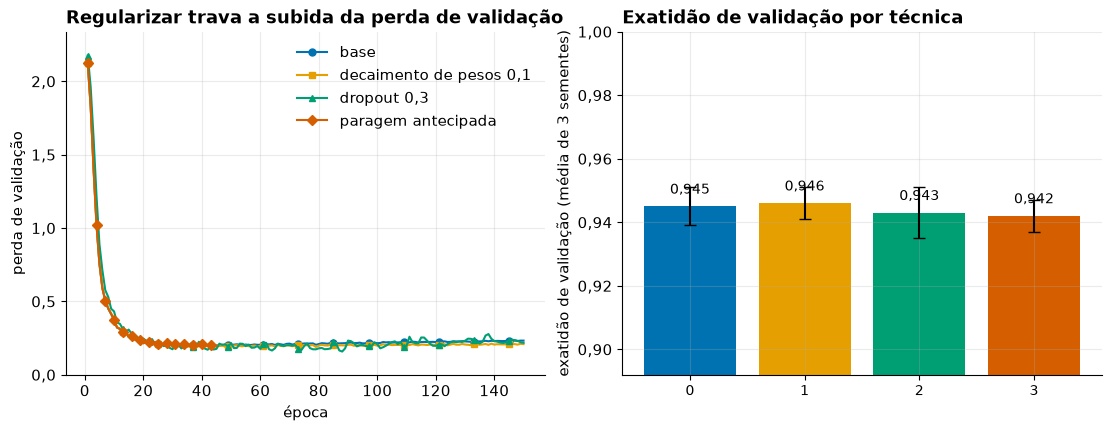

early stopping (seed 0): parou na época 45, melhor época 30


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
plot_history({k: v["loss_va"] for k, v in curves.items()}, ylabel="perda de validação", title="Regularizar trava a subida da perda de validação", ax=axes[0])
axes[0].set_ylim(0, max(curves["base"]["loss_va"]) * 1.1)
bars = table["acc val (média)"]
axes[1].bar(range(len(bars)), bars.values, yerr=table["acc val (desvio)"].values, color=CYCLE[:len(bars)], capsize=4)
axes[1].set_xticks(range(len(bars)), [n.replace(" ", "\n", 1) for n in bars.index], fontsize=10)
axes[1].set(ylim=(bars.min() - 0.05, 1.0), ylabel="exatidão de validação (média de 3 sementes)", title="Exatidão de validação por técnica")
for i, v in enumerate(bars.values): axes[1].text(i, v + 0.004, f"{v:.3f}", ha="center", fontsize=10)
finish(fig, FIG / "04_regularization.png"); plt.show()
if "stopped_at" in curves["paragem antecipada"]:
    print(f"early stopping (seed 0): parou na época {curves['paragem antecipada']['stopped_at']}, melhor época {curves['paragem antecipada']['best_epoch']}")

**Leitura honesta dos resultados:** as três técnicas melhoram a **loss** de validação (≈ 0,21 no modelo base contra ≈ 0,18–0,20), sobretudo o *early stopping* (≈ 0,18), mas a **accuracy** de validação quase não muda (≈ 94,5 %, com desvio de ≈ 0,5 pontos entre seeds). Ou seja, regularizar tornou a rede menos *sobreconfiante* sem a tornar muito mais certeira: com 300 exemplos e 10 classes, o limite está nos dados. Mais dados ajudariam mais do que qualquer técnica.

> ⚠️ **Cuidado:** usámos a validação para **escolher** a época do *early stopping*. Isso torna-a ligeiramente otimista: num projeto a sério guarda-se um **conjunto de teste** à parte, só tocado no fim (como no notebook 01).

### 💬 Discussão — Avaliação: treino a 100 % é bom sinal?

A rede acerta 100 % no treino. Isso é uma boa notícia? Que informação te falta para decidir, e como a obténs?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

Não por si só. Falta saber como se comporta em **dados que não viu**: a curva de validação mostra que a *loss* sobe e a *accuracy* de validação fica abaixo da de treino (ver figura). Essa distância é o *overfitting*. Obtém-se separando uma validação antes de treinar, e comparando regularizadores nas **mesmas** condições (aqui, 3 seeds, porque uma só corrida pode enganar).
</details>

<a id="sec-7"></a>

# 7. 🚀 Deployment · Parte 3 — CPU vs GPU

Treinar e usar redes é, no essencial, **multiplicar matrizes**. Uma multiplicação $n\times n$ requer ≈ $2n^3$ operações em vírgula flutuante (*FLOP*), e as GPUs têm milhares de unidades pequenas para as fazer em paralelo.

Medimos com `src.benchmark`:

- `time_matmul(n, device)`: mediana de várias repetições, com **aquecimento** (a primeira chamada paga custos únicos) e **sincronização** (as chamadas à GPU são assíncronas: sem `torch.cuda.synchronize()` medias só o tempo de lançar a operação);
- `time_transfer(n, "cuda")`: tempo de copiar a matriz CPU → GPU → CPU.

> 💡 **Dica:** o PyTorch que o `uv sync` instala é a versão **só CPU**. Para usar uma GPU NVIDIA **localmente**: `uv pip install torch --index-url https://download.pytorch.org/whl/cu128`. No **Colab** basta escolher *Ambiente de execução → Alterar o tipo → GPU*. Se não houver GPU o notebook corre na mesma, só com a CPU.

In [26]:
from src.benchmark import available_devices, device_name, time_matmul, time_transfer

devices = available_devices()
print("dispositivos:", devices)
for d in devices:
    print(f"  {d:<5} -> {device_name(d)}")

SIZES = [64, 256, 1024, 2048, 4096]
rows = []
for n in SIZES:
    for d in devices:
        r = time_matmul(n, d, repeats=10 if n <= 1024 else 5)
        rows.append({"n": n, "device": d, "ms": r["ms"], "gflops": r["gflops"]})
bench = pd.DataFrame(rows)
bench.pivot(index="n", columns="device", values="ms").round(3).rename_axis(columns="tempo (ms)")

dispositivos: ['cpu', 'cuda']
  cpu   -> AMD64 Family 25 Model 68 Stepping 1, AuthenticAMD · 8 threads
  cuda  -> NVIDIA GeForce RTX 4060 Laptop GPU


tempo (ms),cpu,cuda
n,,
64,0.012,0.050
256,0.116,0.104
1024,16.420,0.407
2048,94.089,2.250
4096,385.557,19.475


In [27]:
gflops = bench.pivot(index="n", columns="device", values="gflops").round(0)
speedup = None
if "cuda" in devices:
    ms = bench.pivot(index="n", columns="device", values="ms")
    speedup = (ms["cpu"] / ms["cuda"]).round(1)
    print("speed-up GPU vs CPU por n:", speedup.to_dict())
transfer = {n: round(time_transfer(n, "cuda"), 3) for n in SIZES} if "cuda" in devices else {}
if transfer:
    print("transferência CPU→GPU→CPU (ms):", transfer)
gflops.rename_axis(columns="GFLOP/s")

speed-up GPU vs CPU por n: {64: 0.2, 256: 1.1, 1024: 40.3, 2048: 41.8, 4096: 19.8}


transferência CPU→GPU→CPU (ms): {64: 0.098, 256: 0.171, 1024: 0.972, 2048: 3.82, 4096: 17.468}


GFLOP/s,cpu,cuda
n,,
64,42.0,10.0
256,290.0,322.0
1024,131.0,5270.0
2048,183.0,7635.0
4096,356.0,7057.0


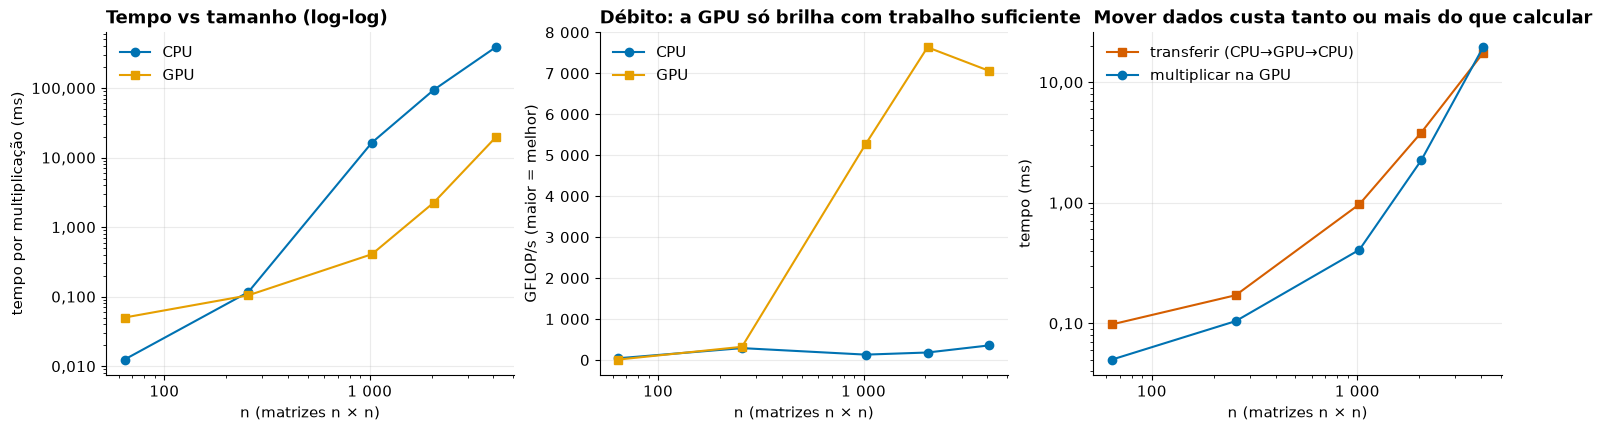

In [28]:
DEV = {"cpu": "CPU", "cuda": "GPU", "mps": "GPU (Apple)"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), layout="constrained")
for d, marker, colour in zip(devices, MARKERS, CYCLE):
    sub = bench[bench.device == d]
    axes[0].plot(sub.n, sub.ms, marker=marker, color=colour, label=DEV.get(d, d))
    axes[1].plot(sub.n, sub.gflops, marker=marker, color=colour, label=DEV.get(d, d))
axes[0].set(xscale="log", yscale="log", xlabel="n (matrizes n × n)", ylabel="tempo por multiplicação (ms)", title="Tempo vs tamanho (log-log)")
axes[1].set(xscale="log", xlabel="n (matrizes n × n)", ylabel="GFLOP/s (maior = melhor)", title="Débito: a GPU só brilha com trabalho suficiente")
if transfer:
    comp = bench[bench.device == "cuda"].set_index("n").ms
    axes[2].plot(SIZES, [transfer[n] for n in SIZES], marker="s", color=PALETTE["red"], label="transferir (CPU→GPU→CPU)")
    axes[2].plot(SIZES, [comp[n] for n in SIZES], marker="o", color=PALETTE["blue"], label="multiplicar na GPU")
    axes[2].set(xscale="log", yscale="log", xlabel="n (matrizes n × n)", ylabel="tempo (ms)", title="Mover dados custa tanto ou mais do que calcular")
    axes[2].legend()
else:
    axes[2].text(0.5, 0.5, "sem GPU nesta máquina\n(corre no Colab com GPU para ver)", ha="center", va="center", transform=axes[2].transAxes)
    axes[2].set_title("Transferência CPU↔GPU"); axes[2].grid(False)
for ax in axes[:2]: ax.legend()
finish(fig, FIG / "04_benchmark.png"); plt.show()

In [29]:
# Resumo em JSON (usado também nos slides): hardware, tempos por n e transferência
hardware = {"cpu": device_name("cpu"), "gpu": device_name("cuda") if "cuda" in devices else None,
            "torch": torch.__version__, "numpy": np.__version__, "python": platform.python_version(),
            "os": platform.platform()}
ms = bench.pivot(index="n", columns="device", values="ms")
summary = {"hardware": hardware,
           "rows": [{"n": int(n), **{f"{d}_ms": round(float(ms.loc[n, d]), 3) for d in devices}} for n in SIZES],
           "transfer_ms": {str(n): v for n, v in transfer.items()}}
print("BENCHMARK_JSON=" + json.dumps(summary, ensure_ascii=False))

BENCHMARK_JSON={"hardware": {"cpu": "AMD64 Family 25 Model 68 Stepping 1, AuthenticAMD · 8 threads", "gpu": "NVIDIA GeForce RTX 4060 Laptop GPU", "torch": "2.11.0+cu128", "numpy": "2.5.5", "python": "3.12.15", "os": "Windows-11-10.0.26300-SP0"}, "rows": [{"n": 64, "cpu_ms": 0.012, "cuda_ms": 0.05}, {"n": 256, "cpu_ms": 0.116, "cuda_ms": 0.104}, {"n": 1024, "cpu_ms": 16.42, "cuda_ms": 0.407}, {"n": 2048, "cpu_ms": 94.089, "cuda_ms": 2.25}, {"n": 4096, "cpu_ms": 385.557, "cuda_ms": 19.475}], "transfer_ms": {"64": 0.098, "256": 0.171, "1024": 0.972, "2048": 3.82, "4096": 17.468}}


### 💬 Discussão — Quando é que a CPU chega?

Olha para os tempos para n = 64 e n = 4096 e para o custo de transferência. Vais comprar uma GPU para uma rede de 64 → 256 → 10 com 1 800 imagens? E para um modelo com biliões de parâmetros?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

Para matrizes pequenas, o tempo é dominado pelo **custo fixo** de lançar a operação e de mover dados, e o débito da GPU está longe do máximo (≈ 10 GFLOP/s em n = 64, contra ≈ 7 000 em matrizes grandes). Nesta máquina (os valores variam um pouco de corrida para corrida): em n = 64 a CPU é ≈ 5–10× mais rápida (≈ 0,01 ms contra ≈ 0,05 ms); em n = 256 empatam (a GPU ganha, no máximo, ≈ 2×); de n = 1024 em diante a GPU ganha ≈ 10–20× (≈ 7 000 GFLOP/s contra ≈ 400–600). Mas só se os dados já estiverem lá: ir e voltar de uma matriz 1024×1024 custa ≈ 1 ms, cerca de 2,5–3× o tempo de a multiplicar na GPU (≈ 0,33 ms) (figura da direita). Para a nossa `Net` (≈ 85 mil parâmetros, 300 imagens) a CPU treina em poucos segundos; a GPU não ajuda. Para modelos de grande escala, não há alternativa: é o paralelismo massivo que torna o treino viável.
</details>

### 💬 Discussão — Implementação: do notebook à produção

Treinaste a `Net` e queres expô-la numa API. Que perguntas fazes antes de escolher entre CPU e GPU para a **inferência**?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

Pergunta-se: qual a **latência** exigida (um pedido de cada vez, onde a CPU costuma bastar, ou milhares por segundo)? Quão grande é o modelo (a nossa cabe em kilobytes)? Quanto custa a GPU parada? Há *batching* possível? Os números do benchmark mostram que a vantagem da GPU depende do tamanho do trabalho; um pedido pequeno não a justifica.
</details>

<a id="sec-8"></a>

# 8. 🧱 Limites e extensões

O que **não** fizemos (e onde continuar):

- **Mais camadas e outras ativações:** o `Net` tem duas escondidas; o `MLP` NumPy tem uma. A profundidade permite hierarquias de *features* (Goodfellow et al., cap. 6).
- **Outros otimizadores:** usámos AdamW; o NumPy usa descida do gradiente simples.
- **Outras arquiteturas** (só menção): **CNN** (convoluções para imagens; AlexNet/ImageNet, Krizhevsky et al., 2012), **transformers** (atenção; Vaswani et al., 2017) e **boosting** (XGBoost/LightGBM, muitas vezes melhores que redes em dados tabulares).
- **Limites:** redes precisam de muitos dados, são sensíveis a hiperparâmetros e difíceis de interpretar; para tabelas pequenas, modelos simples ganham (notebooks 01 e 02).

<a id="sec-9"></a>

# 9. ✏️ Exercícios

### ✏️ Exercício 1 — Perceptrão em NAND

**Dificuldade:** ⭐

O NAND (não-E) tem saída 0 só para (1, 1). O perceptrão consegue aprendê-lo? E o NOR? Treina com `train_perceptron` e confirma pelas previsões.

In [30]:
y_nand = np.array([1, 1, 1, 0.])
# TODO: w, b, erros = train_perceptron(X_gate, y_nand) ... e imprime step(X_gate @ w + b)

<details>
<summary>💡 Ver solução</summary>

NAND e NOR são linearmente separáveis (são as portas "universais" da lógica), por isso o perceptrão converge a 0 erros. Só o XOR (e o XNOR) precisam de uma camada escondida.

```python
for name, t in {'NAND': [1, 1, 1, 0], 'NOR': [1, 0, 0, 0]}.items():
    w, b, err = train_perceptron(X_gate, np.array(t, float))
    print(name, err[-1], step(X_gate @ w + b).astype(int))
```
</details>

### ✏️ Exercício 2 — Quantos neurónios escondidos?

**Dificuldade:** ⭐⭐

Treina `MLP(2, h)` nas luas (lr 0,5, 3000 épocas) com h = 1, 2, 4, 16. Imprime a loss e a *accuracy* de treino e desenha as fronteiras. A partir de que h deixa de compensar?

In [31]:
# TODO: for h in (1, 2, 4, 16): ...

<details>
<summary>💡 Ver solução</summary>

Com h = 1, 2 e 4 a accuracy de treino fica em ≈ 88 % (o mesmo que uma regressão logística, 87,5 %): faltam neurónios para curvar a fronteira o suficiente. Com h = 16 sobe para ≈ 96,8 % e com h = 100 não melhora (≈ 96,8 %). Mais neurónios aumentam o risco de ajustar o ruído: a escolha deve ser feita por **validação**, não por accuracy de treino.

```python
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, h in zip(axes, (1, 2, 4, 16)):
    m = MLP(2, h, seed=0); hist = m.fit(X_moons, y_m, lr=0.5, epochs=3000)
    acc = (m.predict(X_moons) == y_moons).mean()
    plot_decision_boundary(m.predict_proba, X_moons, y_moons, ax=ax, title=f'h={h}: loss {hist["loss"][-1]:.2f}, acc {acc:.0%}')
plt.show()
```
</details>

### ✏️ Exercício 3 — float16 na GPU

**Dificuldade:** ⭐⭐⭐

Mede `time_matmul(4096, 'cuda', dtype='float16')` e compara os GFLOP/s com `float32`. (Se não tiveres GPU, explica em que condições esperavas ganho.)

In [32]:
if 'cuda' in devices:
    pass  # TODO
else:
    print('sem GPU: ver a solução')

<details>
<summary>💡 Ver solução</summary>

Em GPUs modernas, `float16` usa os *tensor cores* e costuma ser várias vezes mais rápido que `float32`, com menos memória e uma precisão mais baixa (daí a *mixed precision* no treino). Na CPU comum, `float16` raramente ganha.

```python
if 'cuda' in devices:
    for dt in ('float32', 'float16'):
        r = time_matmul(4096, 'cuda', dtype=dt, repeats=5)
        print(dt, round(r['ms'], 2), 'ms', round(r['gflops']), 'GFLOP/s')
```
</details>

<a id="sec-10"></a>

# 10. 📌 Resumo

| Ideia | Em uma linha |
|---|---|
| **Perceptrão** | um neurónio = reta; resolve AND/OR, falha no XOR (4 erros por época) |
| **MLP** | $z_1 = XW_1+b_1 \to \tanh \to z_2 \to \sigma$; a camada escondida deforma o espaço |
| **Backprop** | regra da cadeia da *loss* para trás; confirmado pelo *gradient check* (≈ 3·10⁻⁹) |
| **Learning rate** | 0,01 lento, 0,5 e 5 bons, 50 instável (nas luas) |
| **PyTorch** | tensores + autograd + `nn.Module`; o *loop*: forward → loss → backward → step |
| **Overfitting** | loss de treino ↓, de validação ↑; travar com *weight decay*, *dropout*, *early stopping* |
| **CPU vs GPU** | GPU ganha em cálculo grande com dados já lá; em tarefas pequenas, a CPU chega |

**Checklist:** ☐ *shapes* verificadas? ☐ *gradient check* feito? ☐ curva de *loss* desenhada? ☐ validação separada antes do treino? ☐ regularização comparada com mais de uma seed?

<a id="sec-11"></a>

# 11. 📚 Para saber mais

- Goodfellow, Bengio & Courville (2016). *Deep Learning*, MIT Press, cap. 6 (MLP e backprop): <https://www.deeplearningbook.org>.
- PyTorch, *Learn the Basics*: <https://docs.pytorch.org/tutorials/beginner/basics/intro.html>.
- PyTorch, *CUDA semantics* (execução assíncrona e sincronização): <https://docs.pytorch.org/docs/stable/notes/cuda.html>.
- Rosenblatt (1958), o perceptrão; Minsky & Papert (1969), *Perceptrons* (o XOR).
- Krizhevsky, Sutskever & Hinton (2012), AlexNet/ImageNet; Vaswani et al. (2017), *Attention Is All You Need* (menções).
- Chapman et al. (2000). *CRISP-DM 1.0*. SPSS/NCR/DaimlerChrysler.

---
<div align="center">

⬅️ [Anterior: 03 · Aprendizagem não supervisionada](../../02_unsupervised_learning/notebooks/03_Unsupervised_Learning.ipynb) &nbsp;·&nbsp; 🏠 [Lição 02](../../README.md) &nbsp;·&nbsp; [Seguinte: 05 · Projeto de Reinforcement Learning](../../04_reinforcement_learning/notebooks/05_Reinforcement_Learning_Project.ipynb) ➡️

**The AI Learning Hub** · Lição 02 — Machine Learning: fundamentos<br>
Diogo Freitas & João Francisco Botas · Licença MIT

</div>